In [2]:
import sqlite3
import pandas as pd
import numpy as np

DB = r"C:\Users\User\OneDrive - Clemson University\flight-delay-analytics\data\flights.db"

conn = sqlite3.connect(DB)
df = pd.read_sql("""
    SELECT op_unique_carrier, origin, dest, month, day_of_week,
           dep_time, distance, arr_delay
    FROM flights_raw
""", conn)
conn.close()

df = df.dropna()                                      # drop cancelled/diverted flights
df["dep_hour"] = (df["dep_time"] // 100).astype(int)  # 1435 -> 14
df["IsDelayed"] = (df["arr_delay"] > 15).astype(int)  # late by more than 15 min

df = df.sample(n=1_000_000, random_state=42)          # 1M flights is enough and much faster
print(df.shape)
df["IsDelayed"].value_counts(normalize=True)

(1000000, 10)


IsDelayed
0    0.798428
1    0.201572
Name: proportion, dtype: float64

In [3]:
from sklearn.model_selection import train_test_split

categorical = ["op_unique_carrier", "origin", "dest", "month", "day_of_week", "dep_hour"]
numeric = ["distance"]

X = df[categorical + numeric]
y = df["IsDelayed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(800000, 7) (200000, 7)


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),  # text/categories -> 0/1 columns
    ("num", StandardScaler(), numeric),                            # scale distance
])

model = Pipeline([
    ("prep", prep),
    ("logreg", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

model.fit(X_train, y_train)
print("Trained!")

Trained!


In [5]:
proba = model.predict_proba(X_test)[:, 1]    # column 1 = probability of "Delayed"

pd.DataFrame({"prob_delayed": proba[:10].round(3),
              "actual": y_test.values[:10]})

,prob_delayed,actual
0,0.204,0
1,0.386,0
2,0.219,0
3,0.267,0
4,0.598,0
5,0.618,0
6,0.091,0
7,0.545,1
8,0.136,0
9,0.150,0


In [6]:
proba = model.predict_proba(X_test)[:, 1]    # column 1 = probability of "Delayed"

pd.DataFrame({"prob_delayed": proba[:10].round(3),
              "actual": y_test.values[:10]})

,prob_delayed,actual
0,0.204,0
1,0.386,0
2,0.219,0
3,0.267,0
4,0.598,0
5,0.618,0
6,0.091,0
7,0.545,1
8,0.136,0
9,0.150,0


In [7]:
from sklearn.metrics import confusion_matrix

rows = []
for t in [0.3, 0.5, 0.7]:
    pred = (proba >= t).astype(int)          # 1 = delayed, 0 = on time
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"threshold": t,
                 "predicted_delayed": pred.sum(),
                 "TP (caught delay)": tp,
                 "FP (false alarm)": fp,
                 "FN (missed delay)": fn,
                 "TN": tn})

pd.DataFrame(rows)

,threshold,predicted_delayed,TP (caught delay),FP (false alarm),FN (missed delay),TN
0,0.3,158706,37496,121210,2818,38476
1,0.5,86425,27048,59377,13266,100309
2,0.7,18639,8765,9874,31549,149812


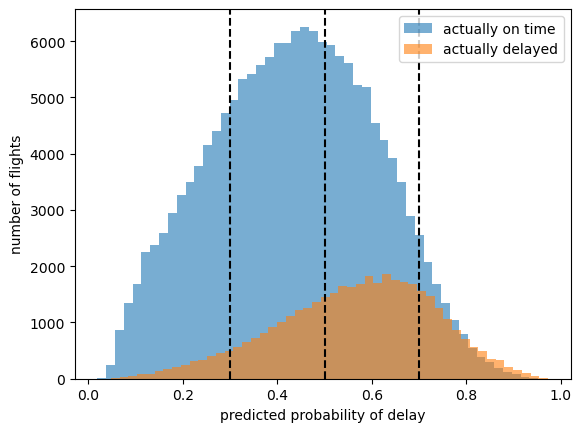

In [8]:
import matplotlib.pyplot as plt

plt.hist(proba[y_test.values == 0], bins=50, alpha=0.6, label="actually on time")
plt.hist(proba[y_test.values == 1], bins=50, alpha=0.6, label="actually delayed")
for t in [0.3, 0.5, 0.7]:
    plt.axvline(t, color="black", linestyle="--")
plt.xlabel("predicted probability of delay"); plt.ylabel("number of flights")
plt.legend(); plt.show()

## What I learned
- Lowering the threshold to 0.3 caught 93% of delays but only 24% of "delayed" predictions were right (many false alarms). Raising it to 0.7 cut false alarms but caught only 22% of delays.
- The threshold is a business choice: low if missing a delay is costly, high if false alarms are costly.
- At 0.5, logistic regression (67% caught, 31% right) performed about the same as my Random Forest (63%, 30%), because both only see schedule features.